# 03 · Weekly cohort retention

Customers are grouped by the week of their first purchase and tracked by `weeks_since_first_purchase`.

**Why weekly, not monthly.** The window covers only three months. Monthly cohorts would give three or four groups, and the later ones would have almost no follow-up time. Weekly cohorts use the same first-purchase method at a finer grain, which gives 14 cohorts and up to 13 follow-up weeks.

**What the metric means.** This is repeat-purchase retention *within the observed window*. A customer's "first purchase" here is the first one this data can see, not necessarily their first ever.

In [4]:
from dotenv import load_dotenv
import psycopg2
import os

load_dotenv(override=True)
conn = psycopg2.connect(os.getenv("SUPABASE_CONNECTION_STRING"))
cur = conn.cursor()
print("Connected successfully")

Connected successfully


In [5]:
cur.execute("""
    WITH first_purchase AS (
        SELECT customer_id, MIN(t_dat) AS cohort_date
        FROM transactions
        GROUP BY customer_id
    )
    SELECT
        t.customer_id,
        DATE_TRUNC('week', fp.cohort_date)::date AS cohort_week,
        DATE_TRUNC('week', t.t_dat)::date AS transaction_week
    FROM transactions t
    JOIN first_purchase fp ON t.customer_id = fp.customer_id;
""")
cohort_raw = cur.fetchall()
print(f"Fetched {len(cohort_raw)} rows")
print(cohort_raw[:5])

Fetched 2029325 rows
[('004528b96ca062a805c009c6a2e810a173fb067d8efc1ca9ed2c5314c5d53e71', datetime.date(2020, 6, 22), datetime.date(2020, 6, 22)), ('008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce838de4d3f9c99cfdce', datetime.date(2020, 6, 22), datetime.date(2020, 6, 22)), ('008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce838de4d3f9c99cfdce', datetime.date(2020, 6, 22), datetime.date(2020, 6, 22)), ('008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce838de4d3f9c99cfdce', datetime.date(2020, 6, 22), datetime.date(2020, 6, 22)), ('008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce838de4d3f9c99cfdce', datetime.date(2020, 6, 22), datetime.date(2020, 6, 22))]


In [6]:
import pandas as pd
cohort_df = pd.DataFrame(cohort_raw, columns=['customer_id', 'cohort_week', 'transaction_week'])

cohort_df['cohort_week'] = pd.to_datetime(cohort_df['cohort_week'])
cohort_df['transaction_week'] = pd.to_datetime(cohort_df['transaction_week'])

cohort_df['weeks_since_first_purchase'] = (
    (cohort_df['transaction_week'] - cohort_df['cohort_week']).dt.days // 7
)

print(cohort_df.head(10))
print()
print("Max weeks since first purchase:", cohort_df['weeks_since_first_purchase'].max())

                                         customer_id cohort_week  \
0  004528b96ca062a805c009c6a2e810a173fb067d8efc1c...  2020-06-22   
1  008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce...  2020-06-22   
2  008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce...  2020-06-22   
3  008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce...  2020-06-22   
4  008d51fe3eea0599fb6d86f6e743f57caa0952fdb5c7ce...  2020-06-22   
5  011089c208ed66a626fff9e1191cca63e40e22984bf36b...  2020-06-22   
6  011089c208ed66a626fff9e1191cca63e40e22984bf36b...  2020-06-22   
7  011089c208ed66a626fff9e1191cca63e40e22984bf36b...  2020-06-22   
8  01283598b576c36586143e9d6c0d41101c46840b140c39...  2020-06-22   
9  01283598b576c36586143e9d6c0d41101c46840b140c39...  2020-06-22   

  transaction_week  weeks_since_first_purchase  
0       2020-06-22                           0  
1       2020-06-22                           0  
2       2020-06-22                           0  
3       2020-06-22                           0  
4     

In [7]:
cohort_counts = (
    cohort_df.groupby(['cohort_week', 'weeks_since_first_purchase'])['customer_id']
    .nunique()
    .reset_index()
)

cohort_pivot = cohort_counts.pivot(
    index='cohort_week',
    columns='weeks_since_first_purchase',
    values='customer_id'
)

print(cohort_pivot)

weeks_since_first_purchase       0        1       2       3       4        5   \
cohort_week                                                                     
2020-06-22                  61829.0  12198.0  9540.0  9398.0  9894.0  10046.0   
2020-06-29                  32914.0   5031.0  4258.0  4345.0  4456.0   4294.0   
2020-07-06                  24076.0   3456.0  3062.0  2817.0  2843.0   2606.0   
2020-07-13                  21005.0   2892.0  2430.0  2293.0  2137.0   2018.0   
2020-07-20                  19837.0   2622.0  2068.0  1761.0  1834.0   2099.0   
2020-07-27                  17956.0   2312.0  1651.0  1425.0  1760.0   1591.0   
2020-08-03                  16563.0   1822.0  1268.0  1446.0  1349.0   1395.0   
2020-08-10                  13069.0   1372.0  1126.0  1071.0  1049.0    885.0   
2020-08-17                  11685.0   1324.0   962.0   888.0   835.0    248.0   
2020-08-24                  13472.0   1427.0  1058.0   872.0   282.0      NaN   
2020-08-31                  

In [8]:
cohort_size = cohort_pivot.iloc[:, 0]
retention_pct = cohort_pivot.divide(cohort_size, axis=0) * 100

print(retention_pct.round(1))

weeks_since_first_purchase     0     1     2     3     4     5     6     7   \
cohort_week                                                                   
2020-06-22                  100.0  19.7  15.4  15.2  16.0  16.2  15.9  14.7   
2020-06-29                  100.0  15.3  12.9  13.2  13.5  13.0  11.9  11.7   
2020-07-06                  100.0  14.4  12.7  11.7  11.8  10.8  10.3  11.9   
2020-07-13                  100.0  13.8  11.6  10.9  10.2   9.6  11.0  10.4   
2020-07-20                  100.0  13.2  10.4   8.9   9.2  10.6   9.2   9.2   
2020-07-27                  100.0  12.9   9.2   7.9   9.8   8.9   9.0   7.5   
2020-08-03                  100.0  11.0   7.7   8.7   8.1   8.4   7.0   2.1   
2020-08-10                  100.0  10.5   8.6   8.2   8.0   6.8   2.2   NaN   
2020-08-17                  100.0  11.3   8.2   7.6   7.1   2.1   NaN   NaN   
2020-08-24                  100.0  10.6   7.9   6.5   2.1   NaN   NaN   NaN   
2020-08-31                  100.0   9.9   7.3   2.0 

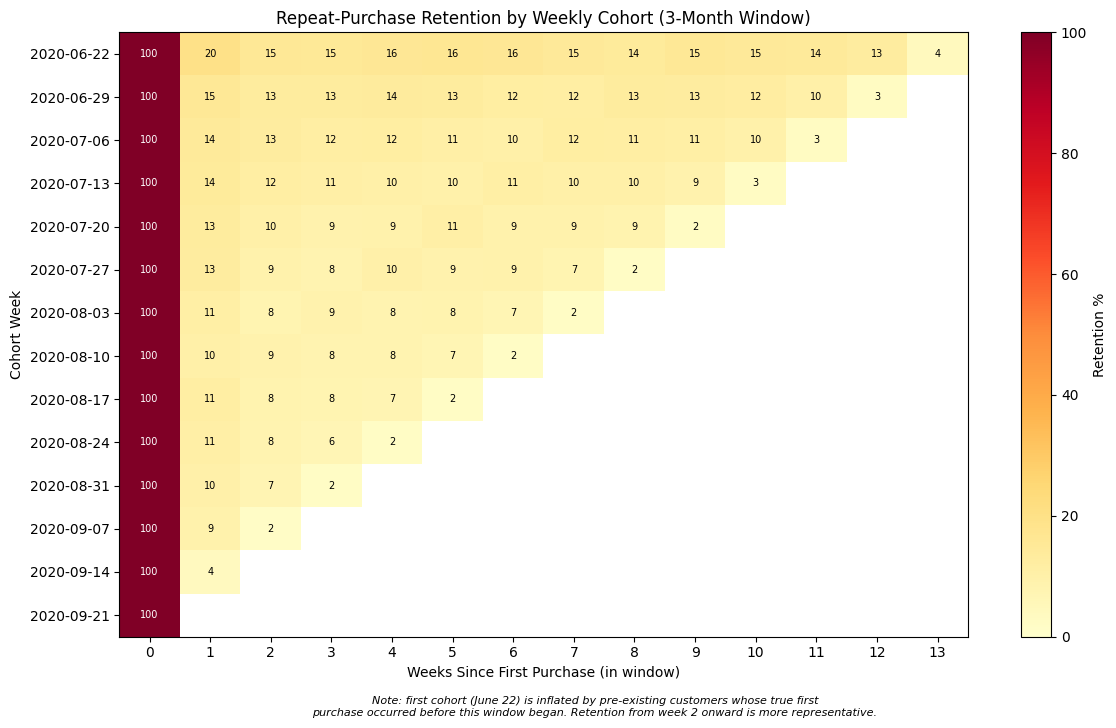

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(retention_pct.values, cmap='YlOrRd', aspect='auto', vmin=0, vmax=100)

ax.set_xticks(range(len(retention_pct.columns)))
ax.set_xticklabels(retention_pct.columns)
ax.set_yticks(range(len(retention_pct.index)))
ax.set_yticklabels([d.strftime('%Y-%m-%d') for d in retention_pct.index])

ax.set_xlabel('Weeks Since First Purchase (in window)')
ax.set_ylabel('Cohort Week')
ax.set_title('Repeat-Purchase Retention by Weekly Cohort (3-Month Window)')

# annotate each cell with its percentage
for i in range(retention_pct.shape[0]):
    for j in range(retention_pct.shape[1]):
        val = retention_pct.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val:.0f}', ha='center', va='center', fontsize=7,
                     color='white' if val > 50 else 'black')

plt.colorbar(im, label='Retention %')
plt.figtext(0.5, -0.03,
            "Note: first cohort (June 22) is inflated by pre-existing customers whose true first\n"
            "purchase occurred before this window began. Retention from week 2 onward is more representative.",
            ha='center', fontsize=8, style='italic')
plt.tight_layout()
plt.savefig('../outputs/figures/cohort_retention_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Read the first row with care.** The week of June 22 cohort (61,829 customers) is nearly double the next cohort (32,914) and several times the size of later ones. Retention is higher too: about 13 to 20% in most weeks, versus roughly 7 to 14% for later cohorts. This is left-censoring, not better customers. Everyone already active before the window who happened to buy in week one gets counted as "new", which sweeps in loyal regulars. Patterns from the second cohort onward are more representative.

The last column of each row is also lower because that week is cut short by the end of the data (Sep 22, 2020).

In [10]:
retention_pct.to_csv('../outputs/summary_tables/cohort_retention.csv')
cohort_pivot.to_csv('../outputs/summary_tables/cohort_counts.csv')
print("Saved cohort analysis outputs")

Saved cohort analysis outputs
